In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mpltransforms
from matplotlib.ticker import MultipleLocator

import seaborn as sns
import os
import datetime
import pickle


from scipy.signal import find_peaks
from sklearn.mixture import GaussianMixture
from astropy.stats.circstats import circvar, circmean
from scipy.stats import pearsonr
from scipy.stats import entropy

from scipy.stats import ranksums, ttest_ind, f_oneway, false_discovery_control
import statsmodels.regression as sm
from statannotations.Annotator import Annotator

from pycircstat2.hypothesis import wheeler_watson_test, watson_u2_test
from pycircstat2 import Circular

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
from src.dataproc import utils, ccutils

### Supporting functions

In [5]:
#### Last updated on 6/21/2026 to align with the definition in Ankit's STM paper
def szred_to_responder(rednum):
    if rednum > 0.9:
        return 'SR'
    elif rednum < 0.5:
        return 'NR'
    else:
        return 'IR'

### Stimulation

In [6]:
save_flag = False

In [7]:
fname_format = 'data/RNSdata/NPEhistograms/%s_Histogram_Hourly.csv'
patcodes_path = 'data/RNSdata/Outcome/Hippo_outcomes_postprocessed_2025April08.csv'
longi_patcodes_path = 'data/RNSdata/Outcome/Hippo_longitudinal_outcomes_postprocessed_2025April08.csv'

outfig_dir = 'output/circpaper_figures/fig04/'

if (not os.path.exists(outfig_dir)) and (save_flag):
    os.mkdir(outfig_dir)
    print('Created directory to save figures.')

In [8]:
outcome_type = 'wtavg_perc_szred'

patcodesdf = pd.read_csv(patcodes_path)

patcodesdf['sz_red'] = patcodesdf[outcome_type].apply(lambda x: -x/100 if x < 0 else 0)

patcodesdf['Responder_Type'] = patcodesdf['sz_red'].apply(lambda x: szred_to_responder(x))

patient_list = ccutils.final_patient_list()

patoutcome_cols = ['npe_code', 'sz_red']

lgpatcodesdf = pd.read_csv(longi_patcodes_path) # longitudinal outcomes

In [9]:
dfdict = {}

npe0041_date_format = "%m/%d/%y %H:%M"

for patient_id in patient_list:
    fname = fname_format %(patient_id)
    if not os.path.exists(fname):
        print(f'{patient_id}: Histogram file doesnt exist.')
        continue
        
    df = pd.read_csv(fname)
    
    if patient_id == 'NPE0041': # update the formatting of time bins for this patient
        df['Region start time'] = df['Region start time'].apply(lambda x: datetime.datetime.strptime(x, npe0041_date_format).isoformat(sep=' '))
    
    df['Local_hour'] = df['Region start time'].apply(lambda x: datetime.datetime.fromisoformat(x).hour)
    df['npe_code'] = patient_id
    df['Responder_Type'] = patcodesdf.loc[patcodesdf['npe_code']==patient_id].Responder_Type.item()
    df['sz_red'] = patcodesdf.loc[patcodesdf['npe_code']==patient_id].sz_red.item()
    df['RX_norm'] = (df['Episode starts with RX'] - df['Episode starts with RX'].mean()) / df['Episode starts with RX'].std()
    max_hour = df.groupby(by='Local_hour')['Episode starts with RX'].mean().idxmax()
    df['Maxalgn_hour'] = (df['Local_hour'] - max_hour)  % 24
    df['Maxalgn_mid_hour'] = ( df['Maxalgn_hour'] - 12 ) % 24
    
    # time from implantation
    implantdt = datetime.datetime.fromisoformat(patcodesdf.loc[patcodesdf['npe_code']==patient_id]['implant_date'].item())
    utils.tfromstart_days(df, datecol='Region start time', start_date=implantdt)
    ccutils.round_half_year_days(df)
    
    dfdict[patient_id] = df.copy()

In [10]:
patcodesdf.loc[(patcodesdf['npe_code'].isin(patient_list))].Responder_Type.value_counts()

Responder_Type
IR    20
NR    10
SR     8
Name: count, dtype: int64

In [11]:
sorted_patient_list = patcodesdf.loc[patcodesdf['npe_code'].isin(patient_list)].sort_values(by='sz_red', 
                                                                                            ascending=False)['npe_code'].to_list()

In [12]:
response_color_dict = {'SR':'tab:blue', 'IR':'purple', 'NR':'tab:red'}
pat_response_colors = {key: response_color_dict[patcodesdf.loc[patcodesdf['npe_code']==key].Responder_Type.item()] 
                       for key in sorted_patient_list}

In [13]:
# normalized stimulation per hour for each patient

normtype = 'zeroone' # 'maxnorm', 'zeroone', 'density', 'zscore', 'nonorm'

msmnormdf_dict = ccutils.mean_stimcounts(dfdict, patient_list, groupby=['Local_hour'], normtype=normtype)

### A: Group level trends

In [14]:
## average

bigmsmdf = []
for patid in sorted_patient_list:   # use sorted_patient_list instead of patient_list for ease of plotting (SR will get solid line)
    patmsmdf = msmnormdf_dict[patid].copy()
    
    patmsmdf.reset_index(inplace=True)
    patmsmdf['npecode'] = patid
    patmsmdf['Responder_Type'] = dfdict[patid]['Responder_Type'].iloc[0]
    patmsmdf['Local_hour_maxrel'] =  ( (patmsmdf['Local_hour'] - patmsmdf.loc[patmsmdf['mean_sc'].idxmax()]['Local_hour'] + 12) % 24 ) - 12
    new_row = patmsmdf.loc[patmsmdf['Local_hour_maxrel'] == -12].copy()
    new_row['Local_hour_maxrel'] = 12
    patmsmdf = pd.concat([patmsmdf, new_row], ignore_index=True)
    bigmsmdf.append(patmsmdf)

# concatenate to get dataframe
bigmsmdf = pd.concat(bigmsmdf, ignore_index=True, axis=0)

In [15]:
### t-test for each sample

hourcol = 'Local_hour_maxrel'
tsstatdf = {hourcol:[], 'pvalue':[]}
for hr in sorted(bigmsmdf[hourcol].unique()):
    sr_series = bigmsmdf.loc[(bigmsmdf['Responder_Type']=='SR') & (bigmsmdf[hourcol]==hr)]['mean_sc'].values
    nr_series = bigmsmdf.loc[(bigmsmdf['Responder_Type']=='NR') & (bigmsmdf[hourcol]==hr)]['mean_sc'].values

    tsstatdf[hourcol].append( hr )
    if hr != 0:
        tsstatdf['pvalue'].append( ttest_ind(sr_series, nr_series).pvalue )
    else:
        tsstatdf['pvalue'].append( 1.0)

# convert to dataframe
tsstatdf = pd.DataFrame(tsstatdf)

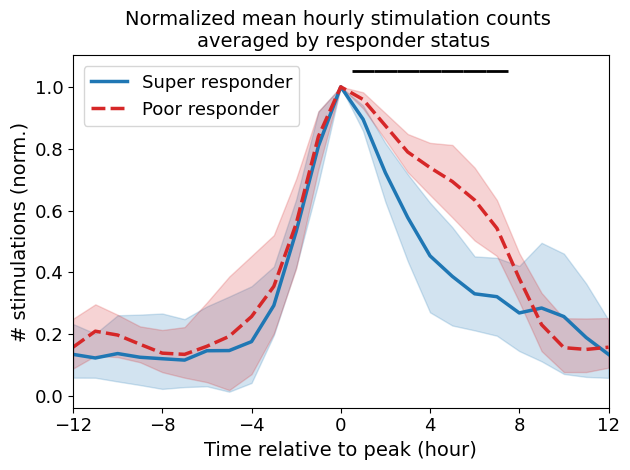

In [16]:
# since SR patients are first followed by IR and NR, simply specifying arguments on lineplot is enough 
# to get the desired ordering and linetype in the lineplots.

ax = sns.lineplot(data=bigmsmdf.loc[bigmsmdf['Responder_Type'].isin(['SR','NR'])], 
                  x='Local_hour_maxrel', y='mean_sc', hue='Responder_Type',
                  hue_order=['SR', 'NR'], style='Responder_Type',
                  palette=response_color_dict, linewidth=2.5)

for idx, row in tsstatdf.loc[tsstatdf['pvalue'] < 0.05].iterrows():
    ax.hlines(y=1.05, xmin=row['Local_hour_maxrel']-0.5, xmax=row['Local_hour_maxrel']+0.5,
              color='k', linewidth=2)

plt.xlim([-12,12])
plt.xticks(ticks=[-12,-8,-4,0,4,8,12])
plt.xlabel('Time relative to peak (hour)', fontsize=14)
plt.ylabel('# stimulations (norm.)', fontsize=14)
plt.tick_params(labelsize=13)

leg_handles, leg_labels = ax.get_legend_handles_labels()
leg_labels = ['Super responder', 'Poor responder']
ax.legend(handles=leg_handles, labels=leg_labels, fontsize=13, loc=[0.02,0.8])

ax.set_title('Normalized mean hourly stimulation counts \n averaged by responder status', fontsize=14)

plt.tight_layout()
if save_flag:
    plt.savefig(outfig_dir + 'group_means_relative_to_maximum.pdf', dpi=300)

plt.show()

In [17]:
tsstatdf.loc[tsstatdf['pvalue'] < 0.05]

,Local_hour_maxrel,pvalue
13,1,0.026582
14,2,0.009821
15,3,0.015618
16,4,0.010090
17,5,0.009459
18,6,0.004678
19,7,0.018944


### B: Schematic of area under curve

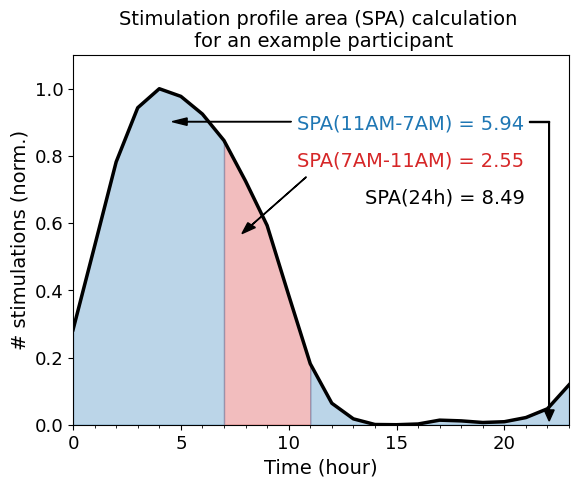

In [18]:
patid = 'NPE0062'
sch_start = 7
sch_end = 11

msmnormdf = msmnormdf_dict[patid].copy()
time_vals = np.array(msmnormdf.index)
stim_vals = msmnormdf.values.flatten()
auc_total = msmnormdf.sum().item()
auc_interval = msmnormdf[sch_start:sch_end].sum().item()
auc_converse = auc_total - auc_interval

fig, ax = plt.subplots(1,1)

plt.plot(time_vals, stim_vals, linewidth=2.5, color='k')
plt.fill_between(time_vals[sch_start:sch_end+1], stim_vals[sch_start:sch_end+1], alpha=0.3, color='tab:red')
plt.fill_between(time_vals[:sch_start+1], stim_vals[:sch_start+1], alpha=0.3, color='tab:blue')
plt.fill_between(time_vals[sch_end:], stim_vals[sch_end:], alpha=0.3, color='tab:blue')

# annotations
plt.text(x=0.68, y=0.8, s='SPA(11AM-7AM) = %0.2f'%(auc_converse), 
         color='tab:blue', ha='center', fontsize=14, transform=ax.transAxes)
plt.arrow(x=0.44, y=0.82, dx=-0.21, dy=0, transform=ax.transAxes, 
          width=0.001, head_width=0.02, color='black')
plt.arrow(x=0.96, y=0.82, dx=0, dy=-0.78, transform=ax.transAxes, 
          width=0.001, head_width=0.02, color='black')
plt.arrow(x=0.92, y=0.82, dx=0.04, dy=0, transform=ax.transAxes, 
          width=0.001, head_width=0.0, color='black')


plt.text(x=0.68, y=0.7, s='SPA(7AM-11AM) = %0.2f'%(auc_interval), 
         color='tab:red', ha='center', fontsize=14, transform=ax.transAxes)
plt.arrow(x=0.47, y=0.67, dx=-0.11, dy=-0.13, transform=ax.transAxes, width=0.001, head_width=0.02, color='black')

plt.text(x=0.75, y=0.6, s='SPA(24h) = %0.2f'%(auc_total), 
         color='black', ha='center', fontsize=14, transform=ax.transAxes)

plt.xlim([0, 23])
plt.ylim([0, 1.1])
ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.xaxis.set_major_locator(MultipleLocator(5))

plt.title(patid, fontsize=14)
plt.xlabel('Time (hour)', fontsize=14)
plt.ylabel('# stimulations (norm.)', fontsize=14)
plt.tick_params(labelsize=13)

ax.set_title(f'Stimulation profile area (SPA) calculation \n for an example participant', 
             fontsize=14)

if save_flag:
    plt.savefig(outfig_dir + 'schematic.pdf', dpi=300)

plt.show()

### C: Scatter plot for total NUS

In [19]:
## calculate area under curve for normalized stimulation counts
aucdf = {key:[] for key in ['npe_code', 'max_hour', 'auc_all', 'auc_day']}

day_start = 7
day_end = 11

for patient_id in patient_list:
    
    df = dfdict[patient_id].copy()
    mean_stim_count_norm = msmnormdf_dict[patient_id].copy()
    
    max_hour = mean_stim_count_norm.idxmax().item()  # hour at which max stim occurs
    max_hour = max_hour if max_hour <= 12 else max_hour-24
    auc_all = mean_stim_count_norm.sum().item()
    auc_day = mean_stim_count_norm[day_start:day_end].sum().item()
    
    # store results
    aucdf['npe_code'].append(patient_id)
    aucdf['max_hour'].append(max_hour)
    aucdf['auc_all'].append(auc_all)
    aucdf['auc_day'].append(auc_day)

# convert to dataframes
aucdf = pd.DataFrame(aucdf)
aucdf['auc_night'] = aucdf['auc_all'] - aucdf['auc_day']

# merge outcome information
aucdf = aucdf.merge(patcodesdf[patoutcome_cols], how='left', on='npe_code')

PearsonRResult(statistic=-0.3991176459418599, pvalue=0.01305513868430026)


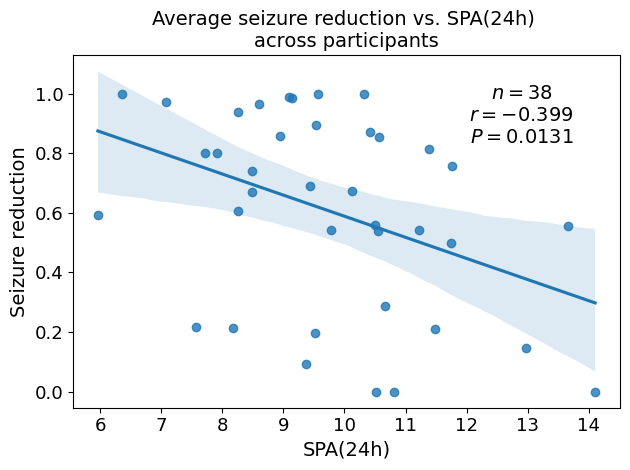

In [20]:
# statistical analysis
xvar = 'auc_all' # 
yvar = 'sz_red'  # 'sz_red', 'log_seizure_rate'

corr_x = aucdf[xvar]
corr_y = aucdf[yvar]
n_samp = len(corr_x)
pearout = pearsonr(corr_x, corr_y)
print(pearout)

ax = sns.regplot(data=aucdf, x=xvar, y=yvar)
plt.text(x=0.82, y=0.75, s=f'$n=%d$\n$r=%0.3f$\n$P=%0.4f$'%(n_samp, pearout.statistic, pearout.pvalue), 
         transform=ax.transAxes, ha='center', fontsize=14)
plt.xlabel('SPA(24h)', fontsize=14)
plt.ylabel('Seizure reduction', fontsize=14)
plt.tick_params(labelsize=13)

plt.title('Average seizure reduction vs. SPA(24h) \nacross participants', fontsize=14)

plt.tight_layout()
if save_flag:
    plt.savefig(outfig_dir + 'totalauc.pdf', dpi=300)

plt.show()

### D: Scatter plot for SPA outside 7-11hr

PearsonRResult(statistic=-0.5038842429548821, pvalue=0.001258541468074406)


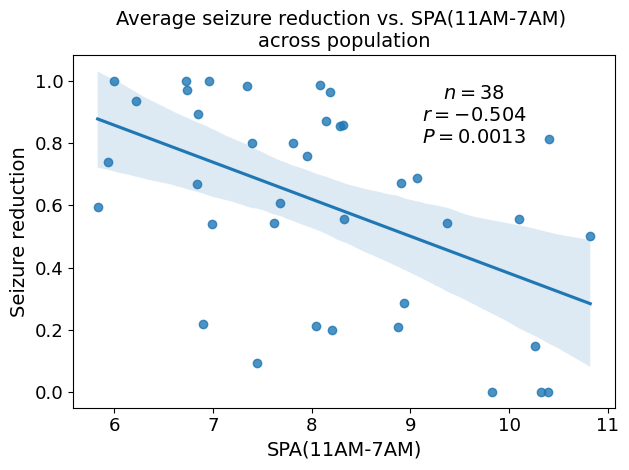

In [21]:
# statistical analysis
xvar = 'auc_night' # 
yvar = 'sz_red'  # 'sz_red', 'log_seizure_rate'

corr_x = aucdf[xvar]
corr_y = aucdf[yvar]
n_samp = len(corr_x)
pearout = pearsonr(corr_x, corr_y)
print(pearout)

ax = sns.regplot(data=aucdf, x=xvar, y=yvar)
plt.text(x=0.74, y=0.75, s=f'$n=%d$\n$r=%0.3f$\n$P=%0.4f$'%(n_samp, pearout.statistic, pearout.pvalue), 
         transform=ax.transAxes, ha='center', fontsize=14)
plt.xlabel('SPA(11AM-7AM)', fontsize=14)
plt.ylabel('Seizure reduction', fontsize=14)
plt.tick_params(labelsize=13)

plt.title(f'Average seizure reduction vs. SPA(11AM-7AM) \nacross population', fontsize=14)

plt.tight_layout()

if save_flag:
    plt.savefig(outfig_dir + 'aucoutside711.pdf', dpi=300)


plt.show()

### E: Sweep over different windows for day/night

In [22]:
per_start_list = np.arange(0, 23, dtype=int)
per_end_list = np.arange(1, 24, dtype=int)
per_pairs = [(ds, de) for ds in per_start_list for de in per_end_list]

In [23]:
# compute association between AUC at night and seizure reduction for different start and end hour windowsß
phmdf = {key:[] for key in ['interval_start', 'interval_end', 'interval_corr', 'interval_pvalue', 
                            'converse_corr', 'converse_pvalue']}  # pvalue heat map df

outcome_var = 'sz_red'

for per_start, per_end in per_pairs:
    
    if per_start >= per_end:
        phmdf['interval_start'].append(per_start)
        phmdf['interval_end'].append(per_end)
        phmdf['interval_corr'].append(np.NaN)
        phmdf['interval_pvalue'].append(np.NaN)
        phmdf['converse_corr'].append(np.NaN)
        phmdf['converse_pvalue'].append(np.NaN)
        
        continue
    
    # if time exists is correct
    aucdf = ccutils.interval_aucdf(msmnormdf_dict, patient_list, per_start, per_end)
    aucdf = aucdf.merge(patcodesdf[patoutcome_cols], on='npe_code')
    
    # compute correlation
    interval_pearout = pearsonr(aucdf['auc_interval'], aucdf[outcome_var])
    converse_pearout = pearsonr(aucdf['auc_converse'], aucdf[outcome_var])
    
    # store results
    phmdf['interval_start'].append(per_start)
    phmdf['interval_end'].append(per_end)
    phmdf['interval_corr'].append(interval_pearout.statistic)
    phmdf['interval_pvalue'].append(interval_pearout.pvalue)
    phmdf['converse_corr'].append(converse_pearout.statistic)
    phmdf['converse_pvalue'].append(converse_pearout.pvalue)
    
# convert the p-value results to dataframe
phmdf = pd.DataFrame(phmdf)

In [24]:
phmdf['interval_corr_sig'] = phmdf.apply(lambda x: x['interval_corr'] if x['interval_pvalue'] < 0.05 else np.NaN, 
                                         axis=1)
phmdf['converse_corr_sig'] = phmdf.apply(lambda x: x['converse_corr'] if x['converse_pvalue'] < 0.05 else np.NaN, 
                                         axis=1)

porcorr = 'corr'  # 'corr'
period_type = 'converse'  # 'interval', 'converse'

heatmapdf = phmdf.pivot(index='interval_start', columns='interval_end', 
                        values=f'{period_type}_{porcorr}_sig').T

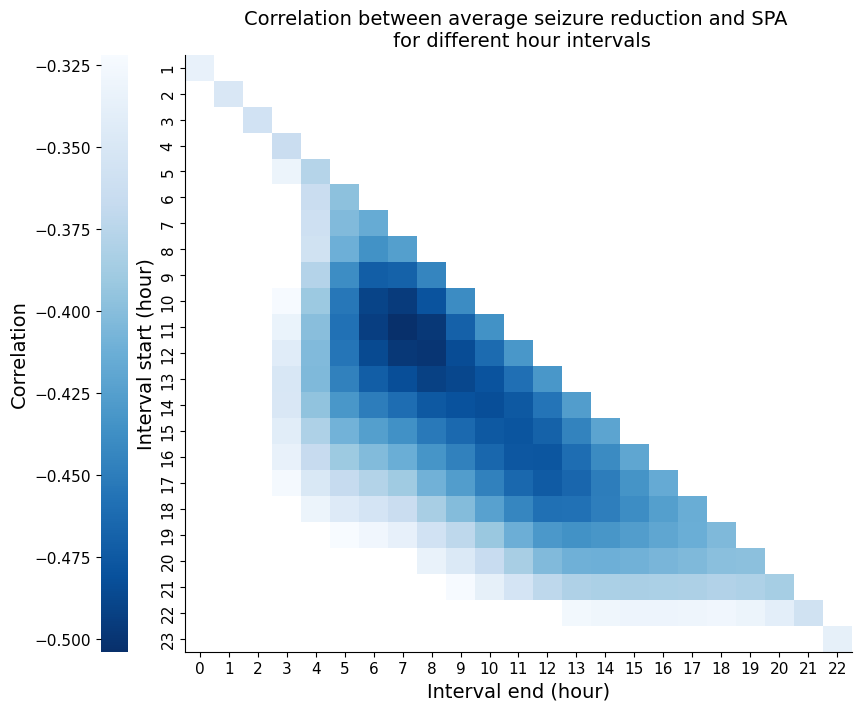

In [25]:
# figure
fig, (cbar_ax, heatmap_ax) = plt.subplots(1, 2, gridspec_kw={'width_ratios': [0.04, 1]}, figsize=(8.5,7), 
                                         layout='constrained')

# heatmap
sns.heatmap(heatmapdf, cmap='Blues_r', annot=False, annot_kws={'fontsize':6}, fmt=".2f", 
            ax=heatmap_ax, cbar_ax=cbar_ax)


# You might want to adjust the colorbar orientation if needed
cbar_ax.yaxis.tick_left() # Ensures ticks are on the left side of the colorbar
cbar_ax.yaxis.set_label_position('left') # Positions the label on the left
cbar_ax.tick_params(labelsize=11)
cbar_ax.set_ylabel('Correlation', fontsize=14)

heatmap_ax.set_xlabel('Interval end (hour)', fontsize=14)
heatmap_ax.set_ylabel('Interval start (hour)', fontsize=14)
heatmap_ax.tick_params(labelsize=11)
heatmap_ax.spines['bottom'].set_visible(True)
heatmap_ax.spines['left'].set_visible(True)

heatmap_ax.set_title('Correlation between average seizure reduction and SPA \n for different hour intervals', 
                    fontsize=14)

if save_flag:
    fig.savefig(outfig_dir + 'heatmap.pdf', dpi=300)

plt.show()

fig.clear()